# Experiment 5: Reinforcement learning (tabular Q-learning)

A 5 x 7 grid world with walls, a goal (+10), a pit (-10) and a step cost of -0.1.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10})

H, W = 5, 7
WALLS = {(1, 2), (2, 2), (3, 2), (1, 4), (2, 4)}
GOAL, PIT, START = (0, W - 1), (2, W - 1), (H - 1, 0)
A = [(-1, 0), (1, 0), (0, -1), (0, 1)]            # up, down, left, right
ARROW = ['↑', '↓', '←', '→']
R_GOAL, R_PIT, R_STEP = 10.0, -10.0, -0.1
ALPHA, GAMMA, EPISODES, CAP, SEED = 0.5, 0.95, 600, 120, 0

def step(s, a, step_cost=R_STEP):
    r, c = s; dr, dc = A[a]; nr, nc = r + dr, c + dc
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c                             # bumping a wall wastes the step
    ns = (nr, nc)
    if ns == GOAL: return ns, R_GOAL, True
    if ns == PIT:  return ns, R_PIT, True
    return ns, step_cost, False

In [2]:
def train(eps, episodes=EPISODES, alpha=ALPHA, gamma=GAMMA, seed=SEED, step_cost=R_STEP):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    curve = []
    for _ in range(episodes):
        s, total = START, 0.0
        for _ in range(CAP):
            if rng.random() < eps:
                a = int(rng.integers(4))                    # explore
            else:
                a = int(np.argmax(Q[s[0], s[1]]))           # exploit
            ns, r, done = step(s, a, step_cost)
            total += r
            target = r + gamma * np.max(Q[ns[0], ns[1]]) * (not done)   # no future at a terminal
            Q[s[0], s[1], a] += alpha * (target - Q[s[0], s[1], a])
            s = ns
            if done:
                break
        curve.append(total)
    return Q, np.array(curve)

def smooth(v, k=25):
    return np.convolve(v, np.ones(k) / k, mode='valid')

## Exploration rate

eps = 0.01: mean return last 100 = 9.08 (5 seeds: 9.09 ± 0.01); first positive episode 3
eps = 0.10: mean return last 100 = 9.00 (5 seeds: 8.79 ± 0.30); first positive episode 1
eps = 0.20: mean return last 100 = 8.86 (5 seeds: 8.84 ± 0.03); first positive episode 3


eps = 0.50: mean return last 100 = 7.44 (5 seeds: 7.46 ± 0.20); first positive episode 2


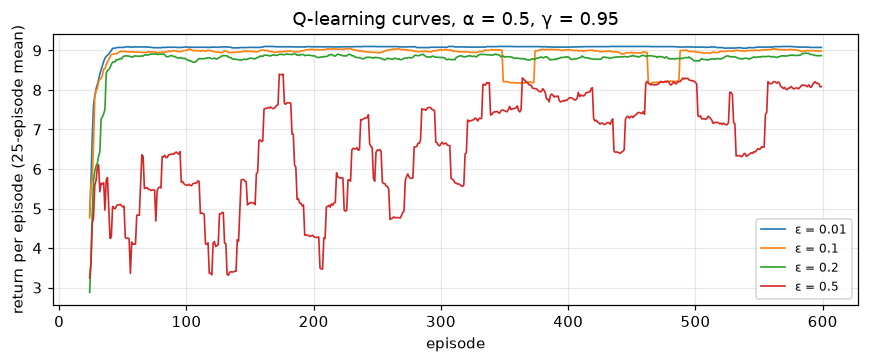

In [3]:
EPS = [0.01, 0.10, 0.20, 0.50]
rows, curves, Qs = [], {}, {}
for eps in EPS:
    Q, curve = train(eps)
    Qs[eps], curves[eps] = Q, curve
    seeds = [train(eps, seed=s)[1][-100:].mean() for s in range(5)]
    first = int(np.argmax(curve > 0))          # first episode that reached the goal with positive return
    rows.append(dict(eps=eps, mean_last100=float(curve[-100:].mean()),
                     seeds_mean=float(np.mean(seeds)), seeds_sd=float(np.std(seeds)),
                     first_positive_episode=first))
    print(f'eps = {eps:.2f}: mean return last 100 = {curve[-100:].mean():.2f} '
          f'(5 seeds: {np.mean(seeds):.2f} ± {np.std(seeds):.2f}); first positive episode {first}')

fig, ax = plt.subplots(figsize=(8, 3.4))
for eps in EPS:
    ax.plot(np.arange(24, EPISODES), smooth(curves[eps]), lw=1.1, label=f'ε = {eps}')
ax.set_xlabel('episode'); ax.set_ylabel('return per episode (25-episode mean)')
ax.set_title('Q-learning curves, α = 0.5, γ = 0.95'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig('figs/fig5_1_learning_curves.png')

## The greedy policy, and whether it is optimal
Value iteration on the known model gives the optimal values; the greedy policy is
optimal if following it from the start earns the optimal return.

In [4]:
def value_iteration(gamma=GAMMA, tol=1e-10):
    V = np.zeros((H, W))
    while True:
        Vn = V.copy()
        for r in range(H):
            for c in range(W):
                if (r, c) in WALLS or (r, c) in (GOAL, PIT):
                    continue
                vals = []
                for a in range(4):
                    ns, rew, done = step((r, c), a)
                    vals.append(rew + gamma * V[ns] * (not done))
                Vn[r, c] = max(vals)
        if np.max(np.abs(Vn - V)) < tol:
            return Vn
        V = Vn

def rollout(policy):
    s, total, path = START, 0.0, [START]
    for _ in range(CAP):
        s, r, done = step(s, int(policy[s]))
        total += r; path.append(s)
        if done:
            break
    return total, path

V = value_iteration()
opt_policy = np.zeros((H, W), dtype=int)
for r in range(H):
    for c in range(W):
        opt_policy[r, c] = int(np.argmax([rew + GAMMA * V[ns] * (not d)
                                          for ns, rew, d in (step((r, c), a) for a in range(4))]))
opt_return, opt_path = rollout(opt_policy)
print(f'optimal return from start = {opt_return:.2f} in {len(opt_path)-1} steps')

policy_check = {}
for eps in EPS:
    pol = np.argmax(Qs[eps], axis=2)
    ret, path = rollout(pol)
    policy_check[eps] = dict(return_=ret, steps=len(path) - 1, optimal=bool(abs(ret - opt_return) < 1e-9))
    print(f'eps = {eps:.2f}: greedy policy return {ret:.2f} in {len(path)-1} steps, optimal = {policy_check[eps]["optimal"]}')

optimal return from start = 9.10 in 10 steps
eps = 0.01: greedy policy return 9.10 in 10 steps, optimal = True
eps = 0.10: greedy policy return 9.10 in 10 steps, optimal = True
eps = 0.20: greedy policy return 9.10 in 10 steps, optimal = True
eps = 0.50: greedy policy return 9.10 in 10 steps, optimal = True


→ → → → → → G
→ ↑ # ↑ # ↑ ↑
↑ ↑ # ↑ # ↑ P
↑ ↑ # ↑ → ↑ ←
↑ → → ↑ → ↑ ←


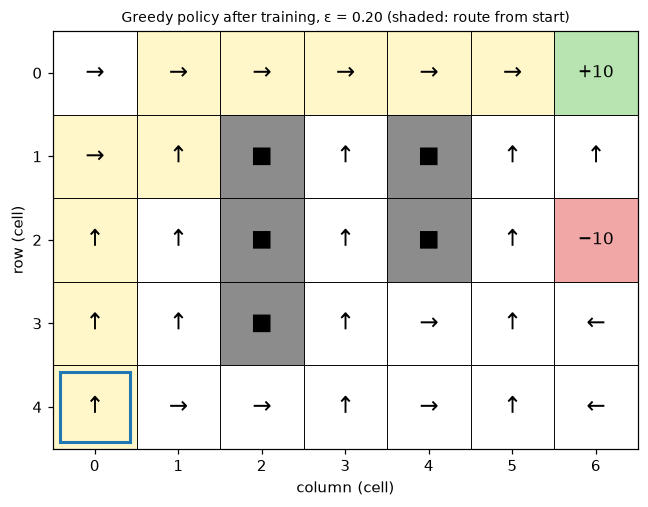

In [5]:
pol = np.argmax(Qs[0.20], axis=2)
_, path = rollout(pol)
grid_txt = []
fig, ax = plt.subplots(figsize=(6.2, 4.6))
for r in range(H):
    line = []
    for c in range(W):
        if (r, c) in WALLS:
            color, txt = '0.55', '■'
        elif (r, c) == GOAL:
            color, txt = '#b7e4b0', '+10'
        elif (r, c) == PIT:
            color, txt = '#f2a7a7', '−10'
        else:
            color, txt = ('#fff6c9' if (r, c) in path else 'white'), ARROW[pol[r, c]]
        ax.add_patch(plt.Rectangle((c, r), 1, 1, facecolor=color, edgecolor='k', lw=0.6))
        ax.text(c + 0.5, r + 0.5, txt, ha='center', va='center', fontsize=15 if len(txt) == 1 else 11)
        line.append({'■': '#', '+10': 'G', '−10': 'P'}.get(txt, txt))
    grid_txt.append(' '.join(line))
ax.add_patch(plt.Rectangle((START[1] + 0.08, START[0] + 0.08), 0.84, 0.84, fill=False, lw=2, ec='tab:blue'))
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect('equal')
ax.set_xticks(np.arange(W) + 0.5); ax.set_xticklabels(range(W))
ax.set_yticks(np.arange(H) + 0.5); ax.set_yticklabels(range(H))
ax.set_xlabel('column (cell)'); ax.set_ylabel('row (cell)')
ax.set_title('Greedy policy after training, ε = 0.20 (shaded: route from start)', fontsize=9)
fig.tight_layout(); fig.savefig('figs/fig5_2_policy.png')
print('\n'.join(grid_txt))

## Without the step cost (viva question 4)

In [6]:
Qn, curve_n = train(0.20, step_cost=0.0)
ret_n, path_n = rollout(np.argmax(Qn, axis=2))
print(f'step cost 0: greedy route length {len(path_n)-1} steps, return {ret_n:.2f}')

step cost 0: greedy route length 10 steps, return 9.10


In [7]:
with open('obs.json', 'w') as fh:
    json.dump(dict(grid=[H, W], walls=sorted(WALLS), goal=GOAL, pit=PIT, start=START,
                   rewards=[R_GOAL, R_STEP, R_PIT], alpha=ALPHA, gamma=GAMMA, episodes=EPISODES,
                   cap=CAP, seed=SEED, rows=rows, opt_return=opt_return, opt_steps=len(opt_path) - 1,
                   policy_check={str(k): v for k, v in policy_check.items()}, policy_grid=grid_txt,
                   no_step_cost=dict(steps=len(path_n) - 1, ret=ret_n)), fh, indent=1)